In [101]:
# Konfiguracja środowiska (Colab ma większość bibliotek; doinstalowujemy brakujące po cichu)
!pip install -q pyyaml joblib

import sys, os, json, random, hashlib, platform, datetime
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn, joblib, yaml
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score
from scipy.stats import chi2_contingency

print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__, "| numpy:", np.__version__)

Python: 3.13.18
scikit-learn: 1.6.1 | pandas: 2.2.3 | numpy: 2.4.6


In [116]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [117]:
# Wczytanie danych - ten sam zbiór na wszystkich laboratoriach
df = pd.read_excel('Baza danych pacjentów 2025 NPI - analiza (1).xlsx')

print(df.head())

   Nr pacjenta      Internal ID    Patient ID Nr na próbce Typ zawału  \
0            1  xxxP20150004938     B00005221   B150104902      No MI   
1            2        B00005431  P20150005143   B150108753      No MI   
2            3        B00005513  P20150005225   B150110316      No MI   
3            4        B00005517  P20150005229   B150110380      No MI   
4            5        B00005528  P20150005239   B150110556      No MI   

        Data pobrania    Płeć      Data urodzenia   EMMPRIN  \
0 2015-09-22 15:08:51  Female 1952-01-01 13:20:38  3089.738   
1 2015-06-10 14:15:05    Male 1957-03-17 00:00:00  3872.500   
2 2015-06-30 14:10:09    Male 1990-06-22 14:10:13  2700.000   
3 2015-06-30 14:37:06  Female 1970-12-25 00:00:00  4177.500   
4 2015-07-06 12:27:29  Female 1948-09-20 00:00:00  2785.000   

   92 kDa               pro-MMP-9  72 kDa pro-MMP-2  Wyniki Klotho pg/ml  \
0                             NaN               NaN             623.7178   
1                        4295.

In [118]:
df[df["Nr pacjenta"].duplicated()==True]
df[df["Internal ID"].duplicated()==True]
df[df["Patient ID"].duplicated()==True]

,Nr pacjenta,Internal ID,Patient ID,Nr na próbce,Typ zawału,Data pobrania,Płeć,Data urodzenia,EMMPRIN,92 kDa pro-MMP-9,72 kDa pro-MMP-2,Wyniki Klotho pg/ml,Wyniki FGF23 pg/ml,TNFalfa [pg/ml],Il-6 [pg/ml],Wiek w momencie zbiórki,Waga (kg),Wzrost (cm),BMI,Obwód bioder,Otyłość BMI >30,Czy pali?,Ile lat pali?,Ilość paczek dziennie,Ile lat nie pali?,Rodzice,Rodzeństwo,Cukrzyca (DM),DM - ile lat?,DM -leczenie,(CAD),CAD - ile lat?,CCS,"Zawał: 0 nigdy, 1 teraz, 2 kiedyś, 3 kiedyś i teraz, a- steMI, b-nsteMI. c- ua",Data obecnego zawału,Data przeszłych zawałów,Przezskórna interwencja wieńcowa (PCI),Data obecnego PCI,Daty przeszłych PCI,PCI naczynie obecne,BMS/DES,Pomostowanie aortalNo-wieńcowe (CABG),Data CABG,Pomosty,Wrodzona wada serca,Jaka?,Nabyta wada serca,Jaka?.1,Zapalenie MIęśnia serca,Data zaplenie serca,Nadciśnienie tętnicze (NT),Ile lat?,Przewlekła niewydolNość serca (CHF),Ile lat?.1,NYHA,Frakcja wyrzutowa lewej komory serca (LVEF),Zaburzenia rytmu,Rodzaj zaburzeń,Ile lat?.2,MIażdżyca kończyn dolnych,Ile lat? Miżdżyca kończyn,MIażdżyca tętnic szyjnych,Ile lat? Miażdżyca t. szyjnych,Zapalenie żył kończyn dolnych/ Zakrzepica,Data zapaenia żył,Zatorowość płucna,Data zatorowości płuc,Stymulator,ICD implantable cardioverter defibrillator,CRT-D device,Ile lat? CRT-D,GFR MIn.,Kidnej Failure<15 ml/MIn/m2,Kidnej insuficiency <60 ml/MIn/m2,Troponiny max.,Cholesterol całkowity (TC),LDL,HDL,Trijglicerydy (TG),NoN-HDL(całkowity -hdl,Kwas moczowy,HbA1C,Zaburzenia homeostazy glukozy >6,Glukoza max. Mg/dl,hsCRP max.,CRP>5 zapalenie,AlbumIny [g/L],RBC przyjęcie,Ht przyjęcie,Hb przyjęcie,WBC przyjęcie,Leukocytoza przyjęcie >10000,MPV przyjęcie,PCT przyjęcie,PDW przyjęcie,P-LCR przyjęcie,PLT przyjęcie,RBC wypis,Ht wypis,Hb wypis,WBC wypis,MPV wypis,PCT wypis,PDW wypis,P-LCR wypis,PLT wypis,ASA,klop,NoAC,ACE-I,ARB,BB,Statyna,MIlurit/diuretyk,Pętlowy,Krwawienie,Brilique
28,29,P20140003549,B00003798,B140075944,No MI,2014-04-18 12:50:20,Female,1943-06-09,NaN,NaN,NaN,309.8156,NaN,4.230000,6.9,71,91.0,164.0,33.834027,124.0,Yes,No,NaN,NaN,NaN,NaN,NaN,Yes,2,Metformax,Yes,NaN,NaN,0,NaN,NaN,0,NaN,NaN,NaN,NaN,No,NaN,NaN,No,NaN,Yes,Wada zastawkowa,No,NaN,Yes,10,No,NaN,NaN,60.0,Yes,NaN,NaN,No,NaN,Yes,NaN,No,NaN,No,NaN,Yes,No,No,NaN,60.0,No,No,0.01,208.0,124.0,38.0,229.0,170.0,7.9,6.2,Yes,114.0,4.41,No,NaN,5.5,46.4,15.2,15.88,Yes,10.9,0.34,13.4,31.6,314.0,5.39,45.3,15.0,12.51,11.2,0.3,14.6,34.2,269.0,Yes,No,No,Yes,NaN,No,Yes,Yes,Yes,NaN,NaN
116,117,P20150005434,B00005737,NaN,No MI,NaT,Male,1955-08-02,NaN,NaN,NaN,NaN,NaN,1.021748,NaN,60,84.0,176.0,27.117769,97.0,No,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,174.0,99.0,52.0,NaN,122.0,NaN,NaN,NaN,NaN,NaN,NaN,31.13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
134,135,P20150005314,B00005608,NaN,No MI,NaT,Male,1947-11-20,NaN,NaN,NaN,NaN,NaN,17.721887,NaN,68,98.0,176.0,31.637397,103.0,Yes,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,128.0,51.0,46.0,157.0,82.0,NaN,NaN,NaN,NaN,NaN,NaN,33.21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


są duble - B00005737. To są dwie różne osoby, mają inną datę urodzne, wzrost, wagę itp

B00005608 - to jest jedna osoba. Zostawiamy bardziej kompletny zbiór danych, drugi usuwamy

B00003798 - dwie różne osoby. Zostawiamy Id pacjenta, bo nie ma dubli, a oprócz tego można go bez ryzyka pokazywać na zewnątrz. Pozsotałe identyfikatory usuwamy.

In [119]:

#Wyrzucamy alternatywne identyfikatory pacjenta - nie potrzebujemy ich
df.drop(['Internal ID', 'Patient ID','Nr na próbce'],
  axis='columns', inplace=True)

#Zasadniczo nie będziemy analizować pod kątem chronologii zdarzeń. Interesuje nas, czy pacjent przez coś przeszedł, a nie kiedy, i w jakiej kolejności.
#To byłoby zbyt skomplikowane, więc wszelkiego rodzaju daty wywalamy z modelu.
df.drop(['Data pobrania', 'Data obecnego zawału', 'Data przeszłych zawałów','Data obecnego PCI','Daty przeszłych PCI',
         'Data zaplenie serca', 'Data zapaenia żył', 'Data zatorowości płuc', 'Ile lat? Miżdżyca kończyn',
         'Ile lat? Miażdżyca t. szyjnych', 'Data CABG'],
  axis='columns', inplace=True)

#Wyrzucamy datę urodzenia, ale wiek będzie w modelu, bo ryzyko zawału zmiena się z wiekiem
df.drop(['Data urodzenia'],
  axis='columns', inplace=True)

#Wyrzucamy wiek i wagę, bo mamy w modelu BMI, obwód bioder i otyłośc BMI > 30!
df.drop(['Waga      (kg)','Wzrost (cm)'],
  axis='columns', inplace=True)

#Ogólnie uważam, że zmienne związane z paleniem papierosów powinny być, ale w tym zbiorze danych są akurat trudne do zinterpretowania poprawnie.
#Zostawimy tylko 'Ile lat pali'.
df.drop(['Czy pali?','Ilość paczek dziennie','Ile lat nie pali?'],
  axis='columns', inplace=True)

#Nie ma wpływu - wywalamy
df.drop(['Rodzice','Rodzeństwo'],
  axis='columns', inplace=True)

#Zbyt mocno powiązana ze zmienną predykcyjną. Wywalamy ze względu na wyciek danych.
df.drop(['Zawał: 0 nigdy, 1 teraz, 2 kiedyś, 3 kiedyś i teraz, a- steMI, b-nsteMI. c- ua'],
  axis='columns', inplace=True)

#Korelacja w drugą stronę - zawał implikuje zmienną
df.drop(['Przewlekła niewydolNość serca (CHF)','Ile lat?', 'Ile lat?.1', 'Ile lat?.2', 'Stymulator', 'ICD implantable cardioverter defibrillator',
'CRT-D device', 'Ile lat? CRT-D', 'Nabyta wada serca', 'NYHA', 'Zaburzenia rytmu',
'Rodzaj zaburzeń', 'Zatorowość płucna'],
  axis='columns', inplace=True)

#Wyrzucamy, bo to jest wykorzystywane główne do rokowań po zawale. To jest morfologia
df.drop(['RBC przyjęcie', 'Ht przyjęcie', 'Hb przyjęcie', 'WBC przyjęcie',
'Leukocytoza przyjęcie >10000', 'MPV przyjęcie', 'PCT przyjęcie', 'PDW przyjęcie',
'P-LCR przyjęcie', 'PLT przyjęcie'],
  axis='columns', inplace=True)

#Wyrzucamy, bo to jest wykorzystywane główne do rokowań po zawale.
df.drop(['Glukoza max. Mg/dl'],
  axis='columns', inplace=True)

#Powód j/w., a dodatkowo to są dane z momentu wypisu ze szpitala. W momencie naszej diagnozy nie będą jeszcze dostępne.
df.drop(['RBC wypis', 'Ht wypis', 'Hb wypis', 'WBC wypis', 'MPV wypis', 'PCT wypis',
'PDW wypis', 'P-LCR wypis','PLT wypis'],
  axis='columns', inplace=True)

#To są podane leki. Zasadniczo nie powinniśmy korzystać z danych o podanych lekach, bo może to powodować wyciek danych. Na pewno część podawanych leków
#jest ze względu na podejrzenie/wiedzę lekarzy o zawale, którą już mają.
df.drop(['ASA', 'NoAC', 'ACE-I', 'ARB', 'BB', 'Statyna',
'MIlurit/diuretyk', 'Brilique'],
  axis='columns', inplace=True)

#Zbyt duże braki w danych - wyrzucamy
df.drop(['AlbumIny [g/L]', 'Kidnej insuficiency <60 ml/MIn/m2',
         'PCI naczynie obecne', 'BMS/DES'],
  axis='columns', inplace=True)

#Nie wiem co to jest...
df.drop(['klop', 'Pętlowy', 'Krwawienie'],
  axis='columns', inplace=True)

#Wiedza medyczna
df.drop(['hsCRP max.', 'Zapalenie MIęśnia serca'],
  axis='columns', inplace=True)

#Brak korelacji matematycznej
df.drop(['Zaburzenia homeostazy glukozy >6', 'CCS', 'Wrodzona wada serca','Nadciśnienie tętnicze (NT)'],
  axis='columns', inplace=True)

#Istnieje już podobna zmienna - cholesterole
df.drop(['NoN-HDL(całkowity -hdl'],
  axis='columns', inplace=True)

#Zmienna nie różnicuje pacjentów - wsyzscy mają taką samą wartość
df.drop(['Kidnej Failure<15 ml/MIn/m2'],
  axis='columns', inplace=True)

#Nie do użycia, bo tekstowa
df.drop(['DM -leczenie', 'Pomosty', 'Jaka?', 'Jaka?.1'],
  axis='columns', inplace=True)

#Wyrzucamy choroby towarzyszące, bo zmienne z liczba lat dla tych chorób maja lepsze korelacje,
#niż same zmienne tak/nie
df.drop(['Cukrzyca  (DM)',' (CAD)'],
  axis='columns', inplace=True)

In [120]:
print(df.head())

   Nr pacjenta Typ zawału    Płeć   EMMPRIN  92 kDa               pro-MMP-9  \
0            1      No MI  Female  3089.738                             NaN   
1            2      No MI    Male  3872.500                        4295.648   
2            3      No MI    Male  2700.000                        4314.063   
3            4      No MI  Female  4177.500                        1991.424   
4            5      No MI  Female  2785.000                        3971.989   

   72 kDa pro-MMP-2  Wyniki Klotho pg/ml  Wyniki FGF23 pg/ml  TNFalfa [pg/ml]  \
0               NaN             623.7178           1571.4230            10.89   
1          1841.437            1105.0032            334.1862             4.90   
2          1627.442             427.1312            347.0178            29.01   
3          1645.984             428.7674            151.1420            21.85   
4          1063.879            1023.5364            179.3065            69.24   

   Il-6 [pg/ml]  Wiek w momencie zbiór

In [121]:
df.loc[df["Płeć"]=="male","Płeć"] = "Male"

In [122]:
df_kategoryczne = ["Typ zawału","Płeć"]
df_skategoryzowane = pd.get_dummies(
    df,
    columns=df_kategoryczne,
    drop_first=True
)

In [123]:
df_skategoryzowane["CRP>5 zapalenie"] = pd.Series(np.where(df["CRP>5 zapalenie"].values == 'Yes', 1, 0),
          df.index)
df_skategoryzowane["Otyłość BMI >30"] = pd.Series(np.where(df["Otyłość BMI >30"].values == 'Yes', 1, 0),
          df.index)
df_skategoryzowane["Pomostowanie aortalNo-wieńcowe (CABG)"] = pd.Series(np.where(df["Pomostowanie aortalNo-wieńcowe (CABG)"].values == 'Yes', 1, 0),
          df.index)
df_skategoryzowane["MIażdżyca kończyn dolnych"] = pd.Series(np.where(df["MIażdżyca kończyn dolnych"].values == 'Yes', 1, 0),
          df.index)
df_skategoryzowane["MIażdżyca tętnic szyjnych"] = pd.Series(np.where(df["MIażdżyca tętnic szyjnych"].values == 'Yes', 1, 0),
          df.index)
df_skategoryzowane["Zapalenie żył kończyn dolnych/ Zakrzepica"] = pd.Series(np.where(df["Zapalenie żył kończyn dolnych/ Zakrzepica"].values == 'Yes', 1, 0),
          df.index)

df_skategoryzowane.loc[df["DM - ile lat?"]=="de Novo","DM - ile lat?"] = 0
df_skategoryzowane.loc[df["DM - ile lat?"]=="od teraz","DM - ile lat?"] = 0
df_skategoryzowane.loc[df["DM - ile lat?"]=="teraz wykryta","DM - ile lat?"] = 0

df_skategoryzowane.loc[df["CAD - ile lat?"]=="de Novo","CAD - ile lat?"] = 0
df_skategoryzowane.loc[df["CAD - ile lat?"]=="2005 (10)","CAD - ile lat?"] = 10
df_skategoryzowane.loc[df["CAD - ile lat?"]==1995,"CAD - ile lat?"] = 20
df_skategoryzowane.loc[df["CAD - ile lat?"]==2001,"CAD - ile lat?"] = 14
df_skategoryzowane.loc[df["CAD - ile lat?"]==2013,"CAD - ile lat?"] = 1
df_skategoryzowane.loc[df["CAD - ile lat?"]==2014,"CAD - ile lat?"] = 1

df_skategoryzowane.loc[df["Przezskórna interwencja wieńcowa (PCI)"]=="Yes","Przezskórna interwencja wieńcowa (PCI)"] = 1

df_skategoryzowane["DM - ile lat?"] = pd.Series(df_skategoryzowane["DM - ile lat?"]).fillna(0)
df_skategoryzowane["CAD - ile lat?"] = pd.Series(df_skategoryzowane["CAD - ile lat?"]).fillna(0)
df_skategoryzowane["Ile lat pali?"] = pd.Series(df_skategoryzowane["Ile lat pali?"]).fillna(0)


/tmp/ipykernel_569/1460438734.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_skategoryzowane["DM - ile lat?"] = pd.Series(df_skategoryzowane["DM - ile lat?"]).fillna(0)
/tmp/ipykernel_569/1460438734.py:28: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_skategoryzowane["CAD - ile lat?"] = pd.Series(df_skategoryzowane["CAD - ile lat?"]).fillna(0)


In [124]:
df_skategoryzowane["CAD - ile lat?"].value_counts()
df_skategoryzowane["DM - ile lat?"].value_counts()

,count
DM - ile lat?,
0,139
5,4
1,2
10,2
20,2
3,1
2,1
12,1
7,1


In [125]:
print(df_skategoryzowane.head())

   Nr pacjenta   EMMPRIN  92 kDa               pro-MMP-9  72 kDa pro-MMP-2  \
0            1  3089.738                             NaN               NaN   
1            2  3872.500                        4295.648          1841.437   
2            3  2700.000                        4314.063          1627.442   
3            4  4177.500                        1991.424          1645.984   
4            5  2785.000                        3971.989          1063.879   

   Wyniki Klotho pg/ml  Wyniki FGF23 pg/ml  TNFalfa [pg/ml]  Il-6 [pg/ml]  \
0             623.7178           1571.4230            10.89          6.81   
1            1105.0032            334.1862             4.90          7.12   
2             427.1312            347.0178            29.01          3.20   
3             428.7674            151.1420            21.85          9.46   
4            1023.5364            179.3065            69.24         14.48   

   Wiek w momencie zbiórki        BMI  Obwód bioder  Otyłość BMI >30

In [126]:
df_skategoryzowane["Przezskórna interwencja wieńcowa (PCI)"].value_counts()

,count
Przezskórna interwencja wieńcowa (PCI),
0,45
1,27
2,8
3,7


,Nr pacjenta,EMMPRIN,92 kDa pro-MMP-9,72 kDa pro-MMP-2,Wyniki Klotho pg/ml,Wyniki FGF23 pg/ml,TNFalfa [pg/ml],Il-6 [pg/ml],Wiek w momencie zbiórki,BMI,Obwód bioder,Otyłość BMI >30,Ile lat pali?,DM - ile lat?,CAD - ile lat?,Przezskórna interwencja wieńcowa (PCI),Pomostowanie aortalNo-wieńcowe (CABG),Frakcja wyrzutowa lewej komory serca (LVEF),MIażdżyca kończyn dolnych,MIażdżyca tętnic szyjnych,Zapalenie żył kończyn dolnych/ Zakrzepica,GFR MIn.,Troponiny max.,Cholesterol całkowity (TC),LDL,HDL,Trijglicerydy (TG),Kwas moczowy,HbA1C,CRP>5 zapalenie,Typ zawału_No MI,Typ zawału_STEMI,Płeć_Male
Nr pacjenta,1.000000,0.121402,-0.481088,-0.139996,-0.266490,0.344161,-0.018221,-0.183245,-0.059825,0.005576,-0.014511,-0.004147,-0.253898,-0.062359,-0.080768,0.674235,-0.034125,-0.468212,-0.105661,-0.168555,-0.166465,0.187222,0.206646,-0.036330,-0.038225,0.013867,-0.003524,-0.176324,0.219328,-0.458112,0.314038,-0.020013,-0.012751
EMMPRIN,0.121402,1.000000,-0.362959,-0.316862,-0.069755,0.014464,0.066826,0.043581,-0.028569,0.045186,0.027054,0.083348,-0.107884,-0.117124,-0.014233,0.246380,-0.181725,-0.210899,-0.099169,-0.095014,-0.000423,-0.289445,0.175790,0.055520,0.051320,0.075144,-0.022186,0.109311,-0.017362,0.132979,0.006548,0.331833,0.050468
92 kDa pro-MMP-9,-0.481088,-0.362959,1.000000,0.280716,0.011316,-0.127189,-0.205419,-0.084046,-0.034710,-0.246285,-0.234544,-0.196060,-0.110634,-0.078174,0.085004,-0.262070,0.120996,0.016955,-0.048923,-0.152077,-0.000431,0.019683,-0.152312,0.093709,0.083993,0.216315,-0.142570,-0.047969,-0.054157,0.088866,0.116335,-0.778698,-0.094792
72 kDa pro-MMP-2,-0.139996,-0.316862,0.280716,1.000000,0.062664,0.064760,-0.201655,-0.118239,0.200997,-0.095135,-0.011132,0.002936,0.025279,0.024331,0.210307,-0.228781,0.131051,0.106133,-0.005141,0.073260,-0.062590,0.001852,-0.156489,0.055389,0.055776,-0.048157,0.097466,0.038850,-0.050086,-0.006436,0.018036,-0.501004,-0.087577
Wyniki Klotho pg/ml,-0.266490,-0.069755,0.011316,0.062664,1.000000,0.055520,0.081594,0.042275,0.003937,-0.121183,-0.113752,-0.024228,0.034000,0.014650,-0.159556,-0.145856,-0.079927,0.147624,-0.106070,-0.171655,0.045638,0.011105,-0.180668,-0.035494,-0.031856,0.057160,-0.095019,-0.105867,-0.024634,-0.243340,0.227482,-0.184596,-0.152667
Wyniki FGF23 pg/ml,0.344161,0.014464,-0.127189,0.064760,0.055520,1.000000,-0.070420,0.104584,-0.082114,0.123871,-0.036123,0.159782,0.121251,0.158163,0.131981,0.361785,0.161523,-0.202260,-0.057765,-0.115963,-0.129466,0.190800,0.066240,0.023030,0.029636,-0.101661,0.108424,-0.196049,0.109792,0.071431,-0.343276,0.244532,0.142965
TNFalfa [pg/ml],-0.018221,0.066826,-0.205419,-0.201655,0.081594,-0.070420,1.000000,0.582286,0.050152,-0.035531,-0.178225,-0.014182,0.050450,0.005953,-0.053160,-0.056796,-0.023940,0.052207,-0.004010,-0.038017,0.164074,-0.061443,-0.004242,-0.024052,-0.005574,-0.023726,-0.058757,0.049982,0.024652,-0.006051,-0.006947,0.057017,0.111622
Il-6 [pg/ml],-0.183245,0.043581,-0.084046,-0.118239,0.042275,0.104584,0.582286,1.000000,0.051948,-0.107277,-0.114025,-0.067217,-0.024670,-0.098887,-0.122654,-0.130824,-0.084259,0.065797,-0.024486,-0.016174,-0.029353,-0.095395,-0.017033,-0.116898,-0.083341,-0.071989,-0.113217,0.009777,-0.070520,-0.092380,0.172004,-0.086691,0.123298
Wiek w momencie zbiórki,-0.059825,-0.028569,-0.034710,0.200997,0.003937,-0.082114,0.050152,0.051948,1.000000,-0.095966,-0.190669,-0.039249,0.214693,-0.014812,-0.016759,-0.081001,-0.009683,0.094439,-0.009611,-0.024135,-0.008001,0.045232,-0.027922,-0.014455,0.011789,-0.031659,-0.054798,0.017569,-0.096537,-0.046812,-0.114185,-0.033448,0.057724
BMI,0.005576,0.045186,-0.246285,-0.095135,-0.121183,0.123871,-0.035531,-0.107277,-0.095966,1.000000,0.720319,0.762796,-0.076982,0.137380,0.045401,0.127436,-0.115653,0.100906,0.071182,0.174834,0.143247,0.074655,0.003414,0.096296,0.070206,-0.043820,0.210079,0.283405,0.327535,0.082931,-0.013387,0.125047,0.069519


<Axes: >

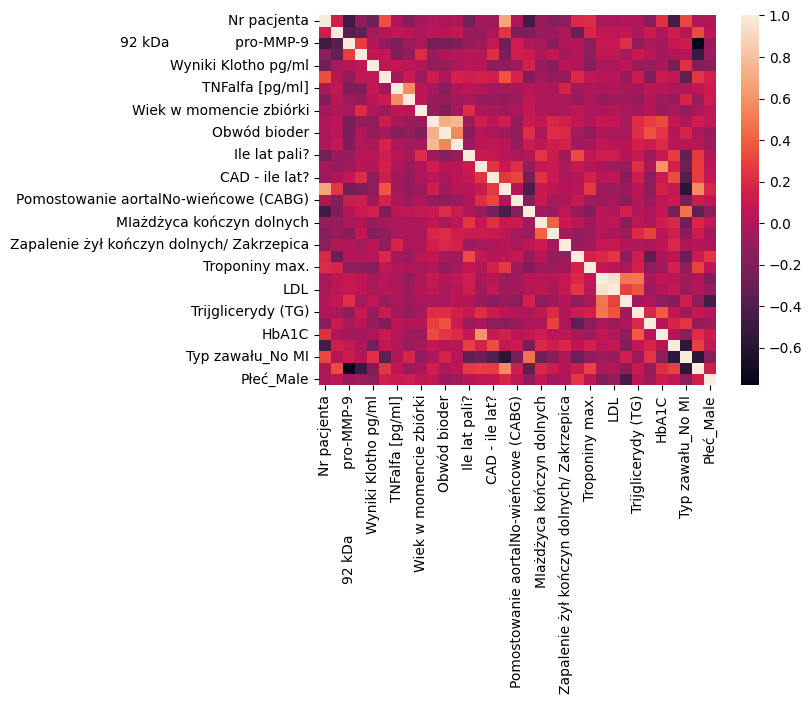

In [127]:
display(df_skategoryzowane.corr())
sns.heatmap(df_skategoryzowane.corr())

In [129]:
print(pom)

                                             Nr pacjenta   EMMPRIN  \
Nr pacjenta                                     1.000000  0.112963   
EMMPRIN                                         0.112963  1.000000   
92 kDa               pro-MMP-9                  0.481088  0.362959   
72 kDa pro-MMP-2                                0.139996  0.316862   
Wyniki Klotho pg/ml                             0.269063  0.068491   
Wyniki FGF23 pg/ml                              0.366356  0.018045   
TNFalfa [pg/ml]                                 0.034355  0.065201   
Il-6 [pg/ml]                                    0.193230  0.041733   
Wiek w momencie zbiórki                         0.008860  0.029343   
BMI                                             0.076589  0.051017   
Obwód bioder                                    0.110402  0.031457   
Otyłość BMI >30                                 0.009268  0.096451   
Ile lat pali?                                   0.079550  0.111559   
DM - ile lat?       

In [128]:
pom = df_skategoryzowane[1:87].corr().abs()
s = pom.unstack()
so = s.sort_values(kind="quicksort")
print(so)

92 kDa               pro-MMP-9               Zapalenie żył kończyn dolnych/ Zakrzepica      0.000431
Zapalenie żył kończyn dolnych/ Zakrzepica    92 kDa               pro-MMP-9                 0.000431
Troponiny max.                               DM - ile lat?                                  0.000986
DM - ile lat?                                Troponiny max.                                 0.000986
CAD - ile lat?                               GFR MIn.                                       0.001143
GFR MIn.                                     CAD - ile lat?                                 0.001143
72 kDa pro-MMP-2                             GFR MIn.                                       0.001852
GFR MIn.                                     72 kDa pro-MMP-2                               0.001852
Zapalenie żył kończyn dolnych/ Zakrzepica    EMMPRIN                                        0.001855
EMMPRIN                                      Zapalenie żył kończyn dolnych/ Zakrzepica     

Na podstawie powyższych korelacji:

*LDL lub Cholersterol całkowity - do wywalenia z modelu. Zbyt skorelowane zmienne.

*BMI lub Otyłość BMI > 30 - do wywalenia

*Obwód bioder lub BMI - do wywalenia

*DM - ile lat lub HbA1C - do wywalenia? Cukrzyca ma korelację z poziomem HbA1C

Reszta raczej do zostawienia - przynajmniej na razie. Korelacje z numerem pacjenta są do zignorowania - tego numeru nie będzie w modelu jako zmiennej